In [7]:
import numpy as np
import rasterio as ras
import matplotlib
import matplotlib.pyplot as plt

print (np.__version__)
print (ras.__version__)
print (matplotlib.__version__)


2.2.6
1.4.4
3.10.5


In [8]:
import zipfile
import os
unzip_path = r'c:\Users\Iconbenz\Downloads\jos_areamap\Browser_images666.zip'
extract_path = r'C:\Users\Iconbenz\Downloads\jos_areamap'



In [9]:
with zipfile.ZipFile(unzip_path, 'r') as ret_zip:
    file_inside = ret_zip.namelist()

    print(f"total file to extract {len(file_inside)}")
    print("extracting now....kindly wait")
    ret_zip.extractall(extract_path)
file = os.listdir(extract_path)

total file to extract 2
extracting now....kindly wait


In [10]:
print(f"total file extracted {len(file)}")
print(file)

total file extracted 4
['2025-02-02-00_00_2025-02-02-23_59_Sentinel-2_L2A_B04_(Raw).tiff', '2025-02-02-00_00_2025-02-02-23_59_Sentinel-2_L2A_B08_(Raw).tiff', 'Browser_images666', 'Browser_images666.zip']


In [11]:
b04_path = r'C:\Users\Iconbenz\Downloads\jos_areamap\2025-02-02-00_00_2025-02-02-23_59_Sentinel-2_L2A_B04_(Raw).tiff'
b08_path = r'C:\Users\Iconbenz\Downloads\jos_areamap\2025-02-02-00_00_2025-02-02-23_59_Sentinel-2_L2A_B08_(Raw).tiff'

In [12]:
with ras.open(b04_path) as src:
    red = src.read(1).astype(np.float32)
    meta = src.meta.copy()

In [13]:
with ras.open(b08_path) as src:
    nir = src.read(1).astype(np.float32)

In [15]:
with np.errstate(divide='ignore', invalid='ignore'):
    ndvi = (nir - red) / (nir + red)
    ndvi[np.isnan(ndvi)] = 0

    print("NDVI calculation complete! Min value:", ndvi.min(), "Max value:", ndvi.max())

NDVI calculation complete! Min value: -1.0 Max value: 1.0


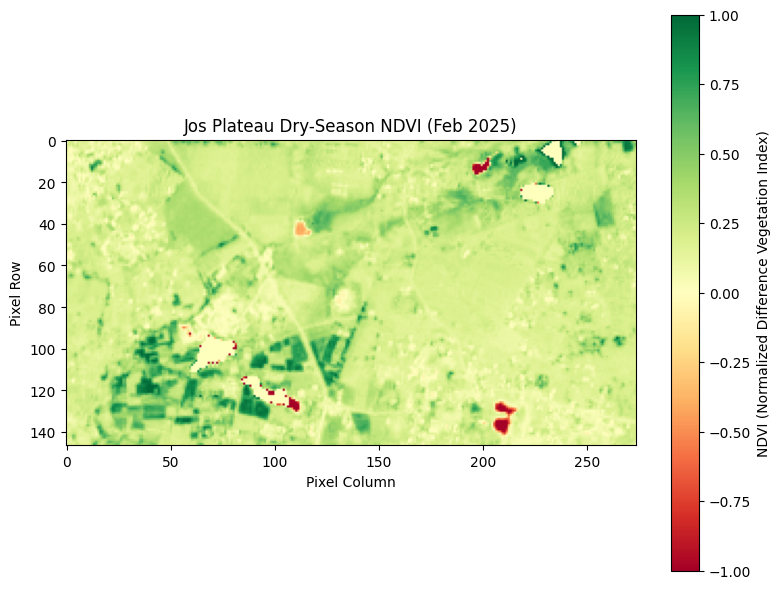

In [16]:
plt.figure(figsize=(8, 6))
plt.imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
plt.colorbar(label='NDVI (Normalized Difference Vegetation Index)')
plt.title('Jos Plateau Dry-Season NDVI (Feb 2025)')
plt.xlabel('Pixel Column')
plt.ylabel('Pixel Row')
plt.tight_layout()
plt.show()

In [18]:
meta.update(
    driver='GTiff',
    dtype=ras.float32,
    count=1 )

In [20]:
output_ndvi_path = r'C:\Users\Iconbenz\Downloads\jos_areamap\Jos_NDVI_Output.tif'
with ras.open(output_ndvi_path, 'w', **meta) as dst:
    dst.write(ndvi.astype(ras.float32), 1)

    print("Saved output GeoTIFF to:", output_ndvi_path)

Saved output GeoTIFF to: C:\Users\Iconbenz\Downloads\jos_areamap\Jos_NDVI_Output.tif
